# 02 — Exploratory data analysis

**Mini Project 2.** Works through the SA2 frame: the variables individually, their
distributions, the suppression problem, the relationships against crowding, and
the spatial structure. Then closes by writing down the feature list that
notebooks 03 and 04 consume.

Nothing downstream is committed to until the last cell of this notebook, which
writes `outputs/feature_spec.json`.

This notebook explores the table and picks the clues, and the final cell saves that list for the next notebooks.

## Setup

In [1]:
import sys
sys.path.append("../src")

import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import json
import mp2

warnings.filterwarnings("ignore", category=pd.errors.PerformanceWarning)

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)

# The download folder, for the shapefiles the spatial join reads.
DATA = Path(r"D:\dsai\dsai_projects\Mini-Project-2-Data")

# Kept here as well as in the join cell, so either can be run alone.
NZTM = mp2.NZTM

# Load the table written by notebook 01.
df = pd.read_csv(mp2.OUT / "analysis_frame.csv")
assert "crowded_n" in df.columns, "crowded_n missing: re-run notebook 01"

print(f"{len(df):,} SA2s loaded, {df.shape[1]} columns")



2,395 SA2s loaded, 94 columns


In [2]:
import geopandas as gpd

# Territorial authority layer. The join to councils is a plain attribute
# lookup, so this cell only reads the file and prints what it contains.
ta_gdf = gpd.read_file(DATA / "territorial-authority-2023-generalised.shp")
print(f"{len(ta_gdf):,} features, CRS {ta_gdf.crs}")

print("\ncolumns:")
for c in ta_gdf.columns.drop("geometry"):
    print(f"  {c:28s} {ta_gdf[c].dtype}   sample: {ta_gdf[c].dropna().iloc[0]!r}")

print("\nfirst row:")
print(ta_gdf.drop(columns="geometry").head(1).T.to_string())



68 features, CRS EPSG:2193

columns:
  TA2023_V1_                   str   sample: '030'
  TA2023_V_1                   str   sample: 'Hastings District'
  TA2023_V_2                   str   sample: 'Hastings District'
  LAND_AREA_                   float64   sample: np.float64(5226.708113569998)
  AREA_SQ_KM                   float64   sample: np.float64(5226.708113569998)
  Shape_Leng                   float64   sample: np.float64(555135.1097126191)

first row:
                            0
TA2023_V1_                030
TA2023_V_1  Hastings District
TA2023_V_2  Hastings District
LAND_AREA_        5226.708114
AREA_SQ_KM        5226.708114
Shape_Leng      555135.109713


### Threshold: top quartile of the SA2 crowding rate
This was chosen over an absolute threshold because a national-average cut (~6%) would leave the positive class too small for recall or PR-AUC to mean anything, and because the client ranks areas for need assessment rather than labelling them.

In [3]:
meta = json.loads((mp2.OUT / "frame_meta.json").read_text())
threshold = meta["top_quartile_threshold"]

A key number to keep in mind: 75% of areas are "not high". So
simply guessing "not high" for every area would be 75% correct
while finding none of the crowded areas. Any result needs to beat
that, not just match it.

## The ranking is noisy at the top

The highest crowding rates in the frame belong to the smallest areas. An SA2 with 3 households where 3 are crowded scores 100%; move one household and it is 67%. Treating SA2s as equally-weighted units biases raw rankings toward tiny areas, so any defensible ranking or size-floor decision needs to account for the denominator (crowding_base).

In [4]:
top_n = 12
cols = ["sa2_name", "crowded_n", "crowding_base", "crowding_rate"]
top_df = df.sort_values("crowding_rate", ascending=False)[cols].head(top_n)

print("most crowded SA2s, with their denominator beside them for sanity check:")
print(top_df.to_string(index=False))
print()

valid = df[df["crowding_base"].notna() & df["crowding_rate"].notna()]
for floor in (20, 50, 100):
    sub = valid[valid["crowding_base"] < floor]
    r_min = sub["crowding_rate"].min()
    r_max = sub["crowding_rate"].max()
    print(f"SA2s under {floor:3d} households: {len(sub):3d}  rate range {r_min:.3f} to {r_max:.3f}")

large_examples = top_df[top_df["crowding_base"] >= 100]
if not large_examples.empty:
    ex_str = ", ".join(
        f"{r.sa2_name} ({r.crowded_n:.1f} / {r.crowding_base:.1f})"
        for r in large_examples.itertuples()
    )
    print(f"\nLarger high-rate SA2s in top {top_n}: {ex_str}")

most crowded SA2s, with their denominator beside them for sanity check:
                          sa2_name  crowded_n  crowding_base  crowding_rate
Islands Thames-Coromandel District        3.0            3.0       1.000000
                         Fiordland        3.0            3.0       1.000000
                      Wesley South        6.0           12.0       0.500000
               Takanini Industrial        3.0            6.0       0.500000
                     Rongomai West      186.0          447.0       0.416107
                          Ferguson      234.0          570.0       0.410526
                        Ōtara West      243.0          612.0       0.397059
                      Māngere West      264.0          675.0       0.391111
                     Harania North      279.0          720.0       0.387500
                        Ōtara East      288.0          753.0       0.382470
                       Ōtara South      210.0          573.0       0.366492
                

## What crowding is in this data

Stats NZ measures household crowding with the Canadian National Occupancy
Standard (CNOS): the number of bedrooms a household needs, given its composition.
The index is published as seven categories plus two totals.

**Collapse.** `crowded` = one or more bedrooms needed, which equals the two
"bedrooms needed" categories summed, to within base-3 rounding. Validated in
notebook 01's reconciliation check.

**Denominator.** `total_stated` — households that gave a usable answer. Dividing
by `total` would include non-response and understate the rate wherever
non-response is higher.


In [5]:
crowding = [c for c in df.columns if c.startswith("household_crowding_index")]

counts  = df[crowding].sum()
stated  = counts["household_crowding_index_total_stated"]

levels = pd.DataFrame({
    "households": counts.round(0),
    "percent_of_stated": (counts / stated * 100).round(2),
})
print(levels.to_string())
print()
print(f"total stated : {stated:,.0f}")
print(f"total        : {counts['household_crowding_index_total']:,.0f}")


                                                                       households  percent_of_stated
household_crowding_index_crowded                                         105633.0               6.20
household_crowding_index_two_or_more_bedrooms_needed_severely_crowded     30861.0               1.81
household_crowding_index_one_bedroom_needed_crowded                       74730.0               4.38
household_crowding_index_not_crowded                                    1598841.0              93.80
household_crowding_index_no_bedrooms_needed_and_none_spare               362940.0              21.29
household_crowding_index_one_bedroom_spare                               548877.0              32.20
household_crowding_index_two_or_more_bedrooms_spare                      686799.0              40.29
household_crowding_index_not_stated                                       75984.0               4.46
household_crowding_index_total                                          1780530.0          

In [6]:
print("collapsed target: crowded (one or more bedrooms needed)")
print(f"  crowded households     : {counts['household_crowding_index_crowded']:>10,.0f}")
print(f"  of stated              : {counts['household_crowding_index_crowded']/stated:>10.2%}")
print(f"  not crowded households : {counts['household_crowding_index_not_crowded']:>10,.0f}")


collapsed target: crowded (one or more bedrooms needed)
  crowded households     :    105,633
  of stated              :      6.20%
  not crowded households :  1,598,841


## Suppression and sentinels

Stats NZ writes two numeric sentinels into the measure columns: `-999` for a
suppressed cell and `-997` for a category not collected or not applicable.

`-999` was caught by notebook 01's reconciliation check. `-997` was caught here,
in a column whose every value was the sentinel — which is why a missing-value
count returned zero for it. `mp2.read_measure` now masks anything at or below
`-990`, so both are handled before the frame is written.

The distribution table below is the check that it worked.


In [7]:
#now I need to re run the distribution code to without the -997 numbers
numeric_features = [c for c in df.columns
                    if c.startswith(("tenure_of_household", "total_household_income",
                                     "number_of_motor_vehicles", "household_composition",
                                     "sector_of_landlord",
                                     "access_to_telecommunication_systems",
                                     "number_of_usual_residents"))]

summary = (df[numeric_features].describe().T[["count", "mean", "std", "min", "50%", "max"]])
summary["missing"] = df[numeric_features].isna().sum()
print(summary.round(2).to_string())


                                                                                                                  count      mean       std      min      50%       max  missing
access_to_telecommunication_systems_total_responses_no_access_to_telecommunication_systems                       2276.0      8.50      8.10      0.0      6.0      93.0      119
access_to_telecommunication_systems_total_responses_access_to_a_cellphone_mobile_phone                           2278.0    668.49    321.17      6.0    654.0    1974.0      117
access_to_telecommunication_systems_total_responses_access_to_a_telephone                                        2276.0    221.59    120.20      0.0    213.0     963.0      119
access_to_telecommunication_systems_total_responses_access_to_a_fax_machine                                         0.0       NaN       NaN      NaN      NaN       NaN     2395
access_to_telecommunication_systems_total_responses_access_to_the_internet                                       22

### Suppression is not missing-at-random

The README claims suppression concentrates in small areas. This measures it, so
the claim has a number behind it. The 112 SA2s that lose the crowding rate
entirely are excluded from the model, and they are systematically the small ones
— which is the model's blind spot, stated rather than glossed.


In [8]:
# any Stats NZ sentinel: -997 and -999 and anything else in that range
numeric = [c for c in df.columns
           if c not in ("sa2_code", "sa2_name") and df[c].dtype == "float64"]
df[numeric] = df[numeric].mask(df[numeric] <= -990)
df = df.copy()

print("columns still holding negatives:",
      int((df[numeric] < 0).any().sum()))
print("cells now missing:", int(df[numeric].isna().sum().sum()))


columns still holding negatives: 0
cells now missing: 12561


In [9]:
#check that there are no other values like this
all_missing = [c for c in numeric if df[c].isna().all()]
print(f"{len(all_missing)} columns are entirely missing and will be dropped:")
for c in all_missing:
    print("   ", c)

df = df.drop(columns=all_missing)
print()
print("frame now:", df.shape)


1 columns are entirely missing and will be dropped:
    access_to_telecommunication_systems_total_responses_access_to_a_fax_machine

frame now: (2395, 93)


### A size floor

`meets_min_size` flags areas with enough households for the rate to be stable.
It is written into the frame so notebooks 03–05 can apply it or argue against it
in one place. The coverage line matters: dropping tiny areas costs very few
households.


In [10]:
small = df["crowding_base"] < 20
print("SA2s under 20 households:", small.sum())
print("their crowding rate range:", 
      f"{df.loc[small,'crowding_rate'].min():.3f} to {df.loc[small,'crowding_rate'].max():.3f}")
print()
print("SA2s under 50 households:", (df['crowding_base'] < 50).sum())
print("SA2s under 100 households:", (df['crowding_base'] < 100).sum())
print()
print(df.nsmallest(12, "crowding_base")[
    ["sa2_name", "crowded_n", "crowding_base", "crowding_rate"]
].to_string(index=False))


SA2s under 20 households: 21
their crowding rate range: 0.000 to 1.000

SA2s under 50 households: 51
SA2s under 100 households: 82

                          sa2_name  crowded_n  crowding_base  crowding_rate
       Oceanic Waikato Region East        0.0            0.0            NaN
           Inlet Waitemata Harbour        0.0            0.0            NaN
         Oceanic West Coast Region        0.0            3.0            0.0
                         Fiordland        3.0            3.0            1.0
             Inlets other Auckland        0.0            3.0            0.0
Islands Thames-Coromandel District        3.0            3.0            1.0
                Inlets Nelson City        0.0            3.0            0.0
               Takanini Industrial        3.0            6.0            0.5
           Inlet Whangārei Harbour        0.0            6.0            0.0
               Bays Waiheke Island        0.0            6.0            0.0
                   Addington Nor

## Relationships against crowding

Three bivariate checks, one point per SA2. These are the evidence that a
multivariate model has signal to find — and the R² values are deliberately
reported, because they are low and that is the argument for using the profile
together rather than any one variable alone.


In [11]:
# The income columns are already in df -- 01 renames them from the lookup
# table. This cell previously merged df into itself, which duplicated the
# columns with _x/_y suffixes and broke the names the scatter cell uses.
income_cols = [c for c in df.columns if "income" in c]
print(f"{len(income_cols)} income columns present in df")
for c in income_cols:
    print(f"  {c:46s} missing {df[c].isna().sum():>5}")


12 income columns present in df
  total_household_income_20_000_or_less          missing   125
  total_household_income_20_001_30_000           missing   125
  total_household_income_30_001_50_000           missing   125
  total_household_income_50_001_70_000           missing   125
  total_household_income_70_001_100_000          missing   125
  total_household_income_100_001_150_000         missing   125
  total_household_income_150_001_200_000         missing   125
  total_household_income_200_001_or_more         missing   125
  total_household_income_not_stated              missing   120
  total_household_income_total                   missing     0
  total_household_income_total_stated            missing   116
  total_household_income_median                  missing   108


In [12]:
crowding_col = "crowding_rate"

rows = []
fits = {}

for col in ["total_household_income_20_000_or_less",
            "total_household_income_100_001_150_000",
            "weekly_rent_paid_by_household_under_200",
            "number_of_motor_vehicles_no_motor_vehicle"]:
    if col not in df.columns:
        print("missing column, skipped:", col)
        continue
    x, y = df[col], df[crowding_col]
    mask = x.notna() & y.notna()
    slope, intercept = np.polyfit(x[mask], y[mask], 1)
    r2 = np.corrcoef(x[mask], y[mask])[0, 1] ** 2
    fits[col] = (slope, intercept, r2)
    rows.append({"feature": col, "n": int(mask.sum()),
                 "slope": f"{slope:.2e}", "r_squared": round(r2, 4)})

print(pd.DataFrame(rows).to_string(index=False))

                                  feature    n     slope  r_squared
    total_household_income_20_000_or_less 2270  5.42e-04     0.0800
   total_household_income_100_001_150_000 2270 -6.38e-06     0.0001
  weekly_rent_paid_by_household_under_200 2230  6.47e-04     0.3293
number_of_motor_vehicles_no_motor_vehicle 2274  1.29e-04     0.0245


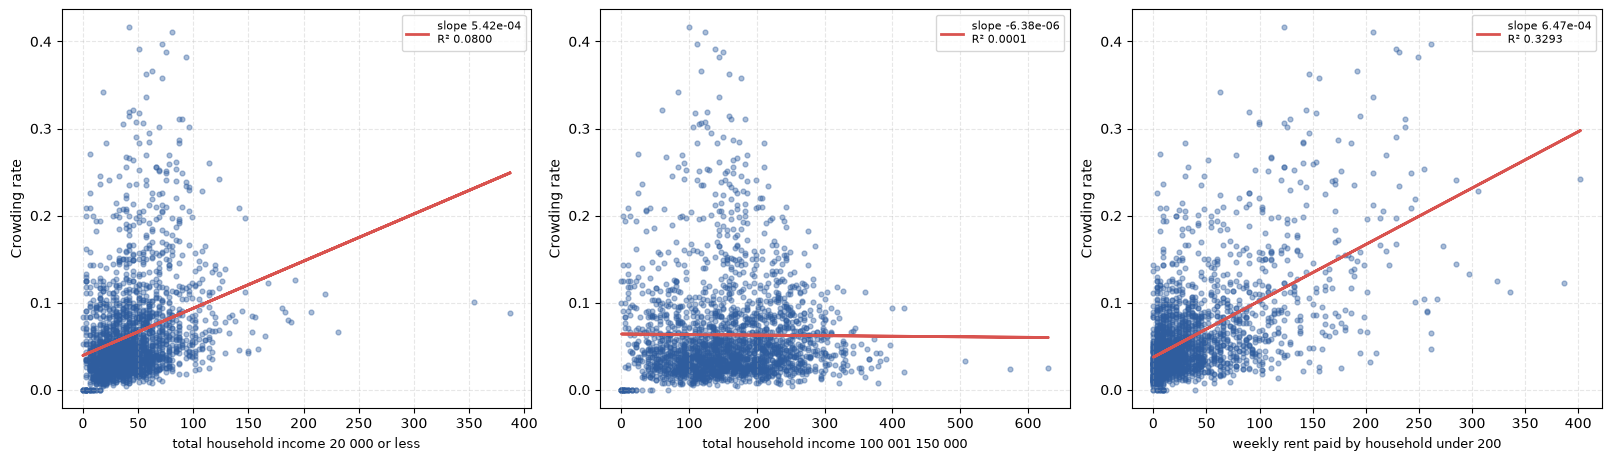

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), layout="constrained")

for ax, (col, (slope, intercept, r2)) in zip(axes, fits.items()):
    x, y = df[col], df[crowding_col]
    mask = x.notna() & y.notna()
    xc, yc = x[mask], y[mask]
    ax.scatter(xc, yc, s=12, alpha=0.4, color="#2F5D9E")
    ax.plot(xc, slope * xc + intercept, color="#D9534F", linewidth=2,
            label=f"slope {slope:.2e}\nR² {r2:.4f}")
    ax.set_xlabel(col.replace("_", " "), fontsize=9)
    ax.set_ylabel("Crowding rate")
    ax.legend(fontsize=8, frameon=True)
    ax.grid(True, linestyle="--", alpha=0.3)

plt.show()

## Spatial structure

Two maps, both from the join in the setup cell: crowding rate by SA2, and the
urban/rural classification the join attached. The premise of the whole project is
that crowding has spatial structure, so it should be visible here.


sa2 shapefile: 2,395 rows
columns: ['SA22023_V1', 'SA22023__1', 'SA22023__2', 'LAND_AREA_', 'AREA_SQ_KM', 'Shape_Leng']
mapped rows: 2,379 | with a crowding rate: 2,283 | no rate: 96


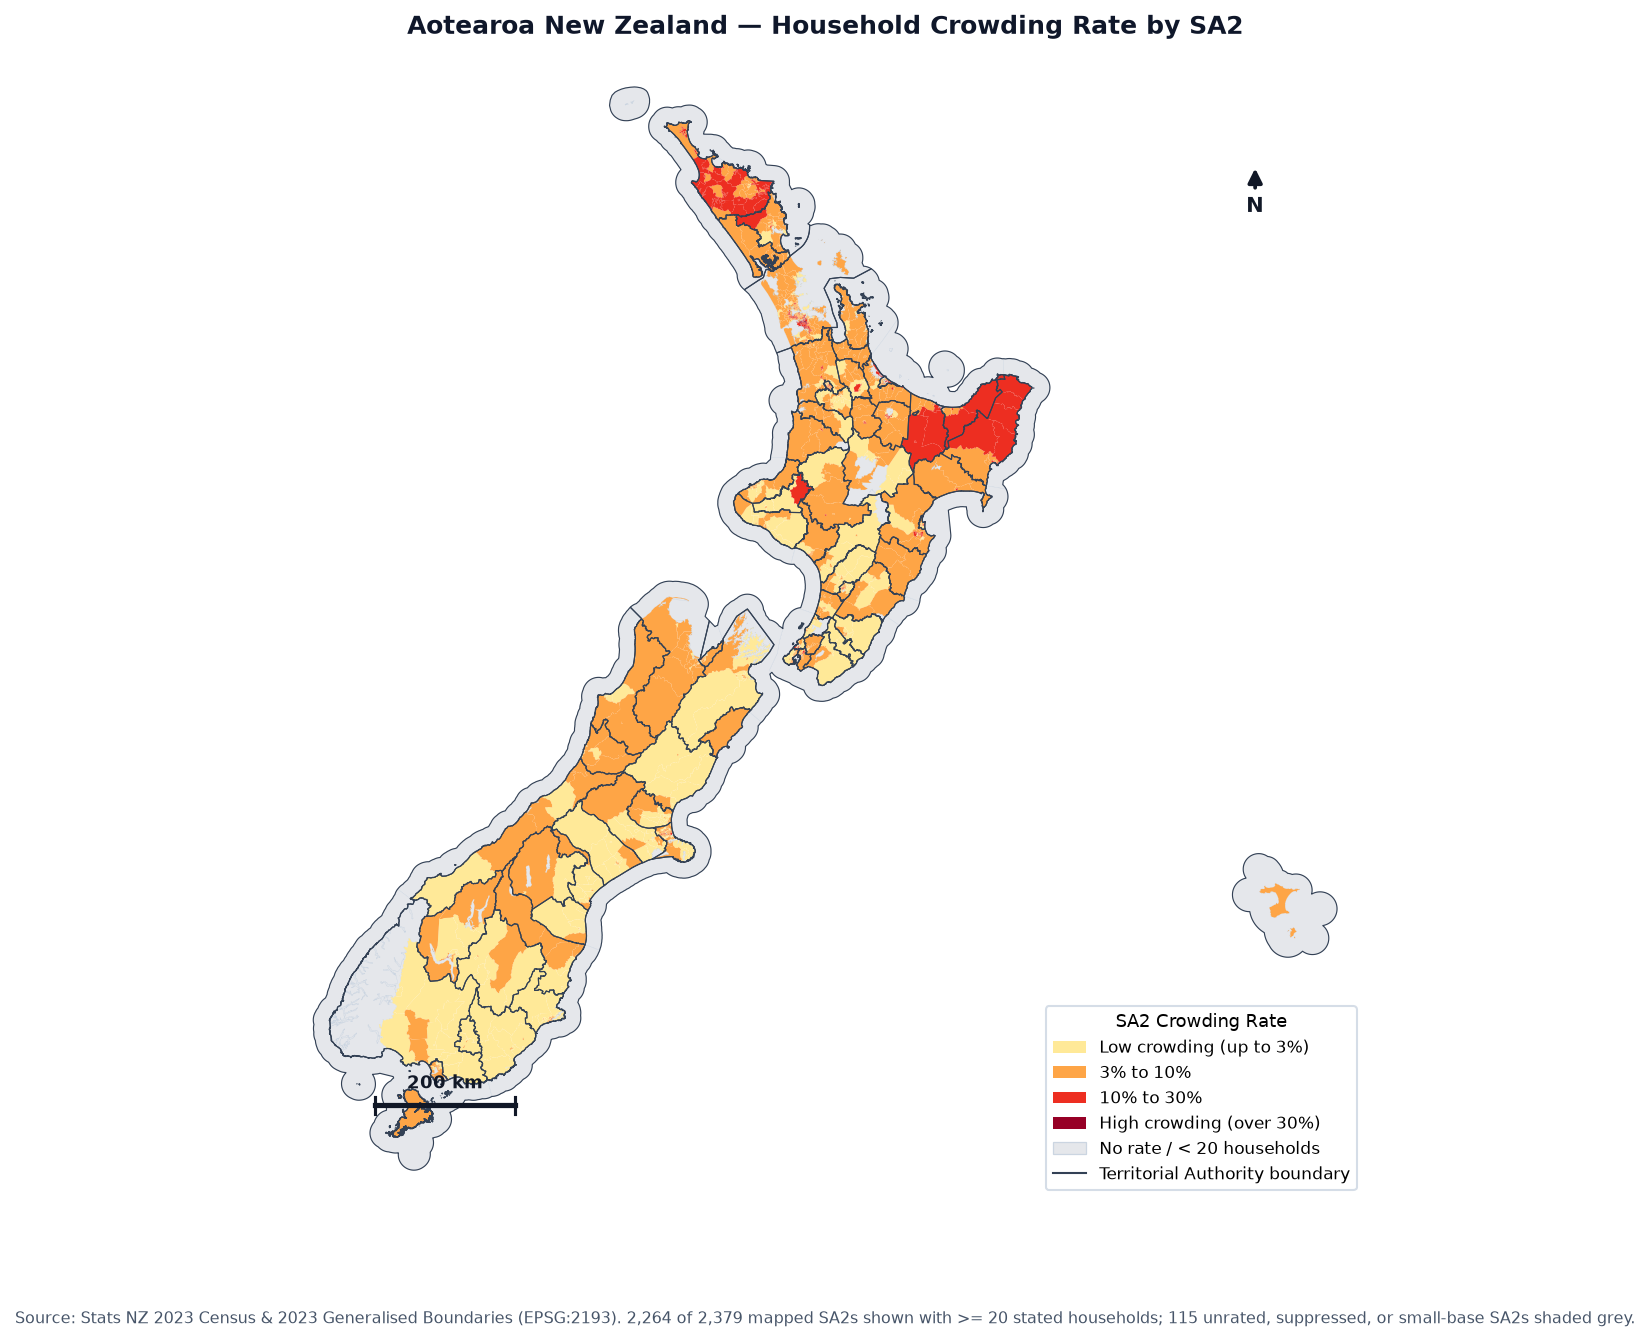

In [14]:
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import geopandas as gpd

# The SA2 shapefile carries codes but NO name column -- its columns are
# SA22023_V1, SA22023__1, SA22023__2, LAND_AREA_, AREA_SQ_KM, Shape_Leng,
# geometry. So the name comes from df, which already has sa2_name.
sa2_shp = gpd.read_file(DATA / "statistical-area-2-2023-generalised.shp")
print(f"sa2 shapefile: {len(sa2_shp):,} rows")
print("columns:", [c for c in sa2_shp.columns if c != "geometry"])

# Normalise the SA2 code on both sides to a plain string of digits.
gdf = sa2_shp[["SA22023_V1", "geometry"]].copy()
gdf["sa2_key"] = gdf["SA22023_V1"].astype(str).str.extract(r"(\d{4,8})", expand=False)
gdf = gdf.drop(columns="SA22023_V1")
gdf = gdf[gdf.geometry.notna() & ~gdf.geometry.is_empty]

if gdf.crs is not None and gdf.crs.to_epsg() != 2193:
    gdf = gdf.to_crs(epsg=2193)

plot_df = df.copy()
plot_df["sa2_key"] = plot_df["sa2_code"].astype(str).str.extract(r"(\d{4,8})", expand=False)

# One row per SA2: the shapefile side is unique, so this cannot inflate.
gdf = gdf.merge(
    plot_df[["sa2_key", "sa2_name", "crowding_rate", "crowding_base"]],
    on="sa2_key", how="left", validate="one_to_one",
)

n_no_rate = int(gdf["crowding_rate"].isna().sum())
print(f"mapped rows: {len(gdf):,} | with a crowding rate: "
      f"{int(gdf['crowding_rate'].notna().sum()):,} | no rate: {n_no_rate:,}")

from matplotlib.colors import ListedColormap
from matplotlib.lines import Line2D

bins = [0.03, 0.10, 0.30, 1.0]
binned_cmap = ListedColormap(plt.cm.YlOrRd([0.15, 0.42, 0.70, 0.95]))

# Exclude missing/zero-denominator rows, plus tiny-denominator SA2s (e.g., Fiordland)
# so sparse/empty areas don't get colored as dark "High crowding".
min_base = 20
plottable_mask = (
    gdf["crowding_rate"].notna()
    & gdf["crowding_base"].notna()
    & (gdf["crowding_base"] >= min_base)
)

fig, ax = plt.subplots(figsize=(7.5, 9.5), dpi=150)
fig.patch.set_facecolor("white")
ax.set_facecolor("white")

# 1. Missing / suppressed / low-denominator SA2s (not colored as high crowding)
gdf[~plottable_mask].plot(
    ax=ax,
    color="#e5e7eb",
    edgecolor="#cbd5e1",
    linewidth=0.15,
    zorder=1,
)

# 2. Binned SA2 crowding rate matching the 4 legend brackets
gdf[plottable_mask].plot(
    column="crowding_rate",
    ax=ax,
    cmap=binned_cmap,
    scheme="UserDefined",
    classification_kwds={"bins": bins},
    edgecolor="none",
    linewidth=0,
    zorder=2,
)

# 3. Territorial Authority boundaries
ta_gdf.boundary.plot(
    ax=ax,
    color="#334155",
    linewidth=0.55,
    zorder=3,
)

# Scale bar (200 km in NZTM / EPSG:2193)
xmin, ymin, xmax, ymax = gdf.total_bounds
sb_x0 = xmin + (xmax - xmin) * 0.06
sb_y0 = ymin + (ymax - ymin) * 0.06
sb_len = 200_000
ax.plot([sb_x0, sb_x0 + sb_len], [sb_y0, sb_y0], color="#111827", linewidth=2.5, zorder=5)
ax.plot([sb_x0, sb_x0], [sb_y0 - 12_000, sb_y0 + 12_000], color="#111827", linewidth=1.5, zorder=5)
ax.plot([sb_x0 + sb_len, sb_x0 + sb_len], [sb_y0 - 12_000, sb_y0 + 12_000],
        color="#111827", linewidth=1.5, zorder=5)
ax.text(sb_x0 + sb_len / 2, sb_y0 + 18_000, "200 km",
        ha="center", va="bottom", fontsize=8.5, fontweight="bold", color="#111827", zorder=5)

# North arrow
nx = xmax - (xmax - xmin) * 0.08
ny = ymax - (ymax - ymin) * 0.12
ax.annotate(
    "N",
    xy=(nx, ny + 75_000),
    xytext=(nx, ny),
    ha="center",
    va="bottom",
    fontsize=10,
    fontweight="bold",
    color="#111827",
    arrowprops=dict(arrowstyle="-|>", color="#111827", lw=1.8, mutation_scale=14),
    zorder=5,
)

bin_colors = binned_cmap.colors
legend_handles = [
    mpatches.Patch(facecolor=bin_colors[0], edgecolor="none", label="Low crowding (up to 3%)"),
    mpatches.Patch(facecolor=bin_colors[1], edgecolor="none", label="3% to 10%"),
    mpatches.Patch(facecolor=bin_colors[2], edgecolor="none", label="10% to 30%"),
    mpatches.Patch(facecolor=bin_colors[3], edgecolor="none", label="High crowding (over 30%)"),
    mpatches.Patch(facecolor="#e5e7eb", edgecolor="#cbd5e1", linewidth=0.6,
                   label=f"No rate / < {min_base} households"),
    Line2D([0], [0], color="#334155", lw=1.0, label="Territorial Authority boundary"),
]
ax.legend(
    handles=legend_handles,
    loc="lower right",
    frameon=True,
    facecolor="white",
    edgecolor="#cbd5e1",
    fontsize=8,
    title="SA2 Crowding Rate",
    title_fontsize=8.5,
)

ax.set_xlim(xmin - 40_000, xmax + 40_000)
ax.set_ylim(ymin - 40_000, ymax + 40_000)
ax.set_axis_off()
ax.set_title(
    "Aotearoa New Zealand — Household Crowding Rate by SA2",
    fontsize=12,
    fontweight="bold",
    color="#0f172a",
    pad=12,
)

n_total_map = len(gdf)
n_plotted = int(plottable_mask.sum())
n_excluded = int((~plottable_mask).sum())
fig.text(
    0.5,
    0.015,
    f"Source: Stats NZ 2023 Census & 2023 Generalised Boundaries (EPSG:2193). "
    f"{n_plotted:,} of {n_total_map:,} mapped SA2s shown with >= {min_base} stated households; "
    f"{n_excluded:,} unrated, suppressed, or small-base SA2s shaded grey.",
    ha="center",
    fontsize=7.5,
    color="#475569",
)

plt.tight_layout(rect=[0, 0.035, 1, 0.97])
plt.show()

In [15]:
print("gdf columns:", list(gdf.columns))

name_col = next(
    (c for c in ["sa2_name", "SA22023_V1_00_NAME", "SA22023__1"] if c in gdf.columns),
    None,
)
code_col = next(
    (c for c in ["sa2_code", "SA22023_V1_00", "SA22023_V1"] if c in gdf.columns),
    None,
)

if name_col is None:
    raise KeyError("No SA2 name column found in gdf; check `gdf.columns` above.")

cols = [c for c in [code_col, name_col, "crowded_n", "crowding_base", "crowding_rate"] if c and c in gdf.columns]

print("\n--- Fiordland rows in gdf ---")
fiordland = gdf[gdf[name_col].astype(str).str.contains("Fiordland", case=False, na=False)][cols]
print(fiordland.to_string(index=False))

if "crowding_rate" in gdf.columns:
    print("\n--- Mapped SA2s > 30% crowding_rate (smallest crowding_base first) ---")
    over_30 = gdf[gdf["crowding_rate"] > 0.30][cols].copy()
    if "crowding_base" in over_30.columns:
        over_30 = over_30.sort_values(["crowding_base", "crowding_rate"], ascending=[True, False])
        print(f"Total > 30%: {len(over_30)}  (with crowding_base < 20: {(over_30['crowding_base'] < 20).sum()})")
    print(over_30.head(15).to_string(index=False))

gdf columns: ['geometry', 'sa2_key', 'sa2_name', 'crowding_rate', 'crowding_base']

--- Fiordland rows in gdf ---
        sa2_name  crowding_base  crowding_rate
       Fiordland            3.0            1.0
Inlets Fiordland            NaN            NaN

--- Mapped SA2s > 30% crowding_rate (smallest crowding_base first) ---
Total > 30%: 27  (with crowding_base < 20: 5)
                          sa2_name  crowding_base  crowding_rate
Islands Thames-Coromandel District            3.0       1.000000
                         Fiordland            3.0       1.000000
               Takanini Industrial            6.0       0.500000
                       Hagley Park            9.0       0.333333
                      Wesley South           12.0       0.500000
                 Massey Road South          369.0       0.341463
                  Ōtara South West          411.0       0.321168
                     Rongomai West          447.0       0.416107
                     Rongomai East        

In [16]:
# urban/rural map removed — TA join is attribute-only.


The number to read off the join: how many SA2s have no single
urban/rural class holding 60% of their area. Those are genuine boundary cases,
and the majority label is the best single label for them but not a strong claim.


In [17]:
# Urban/rural map removed -- the area-weighted overlay was dropped from scope.


In [18]:
import geopandas as gpd

# Ensure SA2 polygons are loaded and in the same CRS (EPSG:2193) as ta_gdf
sa2_path = DATA / "statistical-area-2-2023-generalised.shp"
sa2_geom = gpd.read_file(sa2_path)

if sa2_geom.crs != ta_gdf.crs:
    sa2_geom = sa2_geom.to_crs(ta_gdf.crs)

# Match SA2 code column name in shapefile
sa2_code_col = next(
    c for c in ("sa2_code", "SA22023_V1_00", "SA22023_V1", "SA22023_V1_") if c in sa2_geom.columns
)
ta_name_col = next(
    c for c in ("TA2023_V_1", "TA2023_V_2", "ta_name", "TA2023_V1_00_NAME", "TA2023_V1_NAME", "NAME")
    if c in ta_gdf.columns
)

# Use centroids for clean 1-to-1 point-in-polygon assignment to a Territorial Authority
sa2_pts = sa2_geom[[sa2_code_col, "geometry"]].copy()
sa2_pts["geometry"] = sa2_pts.geometry.centroid

joined = gpd.sjoin(
    sa2_pts,
    ta_gdf[[ta_name_col, "geometry"]],
    how="left",
    predicate="within",
)

# Fallback to nearest TA if any centroid sits slightly outside polygon bounds
unmatched = joined[ta_name_col].isna()
if unmatched.any():
    nearest = gpd.sjoin_nearest(
        joined.loc[unmatched, [sa2_code_col, "geometry"]],
        ta_gdf[[ta_name_col, "geometry"]],
        how="left",
    )
    joined.loc[unmatched, ta_name_col] = nearest[ta_name_col].values

ta_lookup = (
    joined[[sa2_code_col, ta_name_col]]
    .rename(columns={sa2_code_col: "sa2_code", ta_name_col: "ta_name"})
    .drop_duplicates(subset=["sa2_code"])
)

# Ensure join key types match df["sa2_code"]
ta_lookup["sa2_code"] = ta_lookup["sa2_code"].astype(str).str.strip()
df = df.copy()
df["sa2_code"] = df["sa2_code"].astype(str).str.strip()
df = df.drop(columns=["ta_name"], errors="ignore").merge(ta_lookup, on="sa2_code", how="left")

print(f"Attached ta_name to {df['ta_name'].notna().sum():,} / {len(df):,} SA2 rows "
      f"({df['ta_name'].nunique(dropna=True)} TAs)")

Attached ta_name to 2,379 / 2,395 SA2 rows (68 TAs)


## The feature list

Key feature exclusions and transformations for the README and downstream notebooks:

**The target.** Every `household_crowding_index_*` column, plus the derived
`crowding_rate`, `crowded_n`, `crowding_base` and `crowded_top_quartile`.

**The target restated.** Household composition and household size. Crowding is
defined as composition against a bedroom requirement, so these are the outcome in
another form. The brief asks whether the area's *profile* can stand in for a
direct measurement — feeding the measurement itself defeats that. Held out of the
primary list, and available for a sensitivity run in notebook 04.

**Denominators and residuals.** Every `_total`, `_total_stated` and `_median` is
a scale variable or is derived from the brackets it accompanies; `_not_stated` and
`_not_elsewhere_included` are non-response and residual buckets, not profile.
Used to build the shares, then dropped.

**Counts become shares.** A raw bracket count is large in any big suburb
regardless of composition. Dividing each bracket by its own stated total turns it
into a share, which is what makes the clustering reflect composition rather than
area size — the same problem the size floor addresses above.


In [19]:
# ===========================================================================
# Feature selection: convert bracket counts to shares and write outputs/feature_spec.json
# for notebooks 03, 04, and 05 (keys: numeric, categorical, target, leaky_or_id).
# ===========================================================================

import json
import numpy as np
import pandas as pd


def _as_series(frame, col):
    """Return a single Series even if a column name somehow appears more than once."""
    obj = frame[col]
    if isinstance(obj, pd.DataFrame):
        return obj.iloc[:, 0]
    return obj


def _unique_columns(frame):
    """Drop any duplicate column names cleanly so lookups stay unambiguous."""
    if frame.columns.duplicated().any():
        dups = frame.columns[frame.columns.duplicated()].unique().tolist()
        print(f"[info] Removed {len(dups)} duplicate column name(s) on df.")
        return frame.loc[:, ~frame.columns.duplicated()].copy()
    return frame


# Remove any *_share columns left over from a prior run before rebuilding
prior_shares = [c for c in df.columns if c.endswith("_share")]
if prior_shares:
    df = df.drop(columns=prior_shares)

df = _unique_columns(df)

# ---------------------------------------------------------------------------
# 1. Exclusion rules (target, outcome-restated, and non-profile columns)
# ---------------------------------------------------------------------------
TARGET_PREFIX = "household_crowding_index_"
DERIVED_TARGET = {
    "crowded_n",
    "crowding_base",
    "crowding_rate",
    "crowded_top_quartile",
}

# Household size and composition restate crowding (bedroom need vs. composition),
# so they are held out of the primary feature set.
DEFINITION_PREFIXES = (
    "household_composition_",
    "number_of_usual_residents_in_household_",
    "count_of_households_in_occupied_private_dwellings",
)

DROP_SUFFIXES = (
    "_total_stated",
    "_total",
    "_median",
    "_not_stated",
    "_not_elsewhere_included",
    "_unidentifiable",
    "_average",
    "_total_share",
    "_median_share",
)


def _excluded_role(col):
    if col.startswith(TARGET_PREFIX) or col in DERIVED_TARGET:
        return "target"
    if any(col.startswith(p) for p in DEFINITION_PREFIXES):
        return "definition"
    return None


# ---------------------------------------------------------------------------
# 2. Bracket families and share denominators
# ---------------------------------------------------------------------------
SHARE_FAMILIES = {
    "total_household_income": "total_household_income_total_stated",
    "weekly_rent_paid_by_household": "weekly_rent_paid_by_household_total_stated",
    "sector_of_landlord": "sector_of_landlord_total_stated",
    "tenure_of_household": "tenure_of_household_total_stated",
    "number_of_motor_vehicles": "number_of_motor_vehicles_total_stated",
    "access_to_telecommunication_systems_total_responses": (
        "access_to_telecommunication_systems_total_responses_total_stated"
    ),
}


def _share_denominator(col):
    if col in SHARE_FAMILIES.values() or col.endswith(DROP_SUFFIXES):
        return None
    for prefix, denom in SHARE_FAMILIES.items():
        if col.startswith(prefix + "_"):
            return denom
    return None


# ---------------------------------------------------------------------------
# 3. Classify numeric columns
# ---------------------------------------------------------------------------
measure_cols = [
    c
    for c in df.columns
    if c not in ("sa2_code", "sa2_name") and pd.api.types.is_numeric_dtype(_as_series(df, c))
]

rows = []
for col in measure_cols:
    role = _excluded_role(col)
    if role is not None:
        rows.append({"column": col, "role": role, "denominator": None})
        continue

    denom = _share_denominator(col)
    if denom is not None:
        rows.append({"column": col, "role": "share", "denominator": denom})
    elif col.endswith(DROP_SUFFIXES):
        rows.append({"column": col, "role": "denominator_or_residual", "denominator": None})
    else:
        rows.append({"column": col, "role": "keep", "denominator": None})

roles = pd.DataFrame(rows)

print("=== Column Classification Summary ===")
for role_name, cnt in roles["role"].value_counts().items():
    print(f"  {role_name:<26} {cnt:3d}")
print()

# ---------------------------------------------------------------------------
# 4. Build share columns in one concat and assemble NUMERIC
# ---------------------------------------------------------------------------
share_rows = roles[roles["role"] == "share"].copy()

missing_denoms = sorted({d for d in share_rows["denominator"] if d not in df.columns})
if missing_denoms:
    raise KeyError(f"Share denominators not in the frame: {missing_denoms}")

share_cols = {}
for _, r in share_rows.iterrows():
    col, denom = r["column"], r["denominator"]
    num_s = _as_series(df, col).astype("float64")
    den_s = _as_series(df, denom).astype("float64").replace(0, np.nan)
    share_cols[f"{col}_share"] = num_s / den_s

if share_cols:
    df = pd.concat([df, pd.DataFrame(share_cols, index=df.index)], axis=1)
    df = _unique_columns(df)

NUMERIC = list(roles.loc[roles["role"] == "keep", "column"]) + [
    f"{c}_share" for c in share_rows["column"]
]

# Drop any candidate numeric column that has zero observed values across all rows.
dropped_all_missing = [c for c in NUMERIC if bool(_as_series(df, c).isna().all())]
if dropped_all_missing:
    NUMERIC = [c for c in NUMERIC if c not in dropped_all_missing]

print(f"Built {len(share_cols)} share columns; dropped {len(dropped_all_missing)} all-missing feature(s).")
for col in dropped_all_missing:
    print(f"  - dropped (all NaN): {col}")
print()

# ---------------------------------------------------------------------------
# 5. Select non-numeric categorical columns
# ---------------------------------------------------------------------------
CATEGORICAL = [
    c
    for c in df.columns
    if not pd.api.types.is_numeric_dtype(_as_series(df, c))
    and c not in ("sa2_name", "geometry")
]

# ---------------------------------------------------------------------------
# 6. Verify feature list and check family share sums
# ---------------------------------------------------------------------------
leaked = [c for c in NUMERIC + CATEGORICAL if _excluded_role(c) is not None]
assert not leaked, f"Excluded columns reached feature list: {leaked}"

print("=== Family Share Sum Checks ===")
for prefix, denom in SHARE_FAMILIES.items():
    fam = [c for c in NUMERIC if c.startswith(prefix + "_") and c.endswith("_share")]
    if not fam or denom not in df.columns:
        continue
    valid_mask = _as_series(df, denom).notna()
    totals = df.loc[valid_mask, fam].sum(axis=1, min_count=1)
    mode = "multi-response" if "telecommunication_systems" in prefix else "single-choice"
    print(
        f"  {prefix:<52} [{mode:<14}] n={len(fam):2d} | "
        f"med={totals.median():.3f} | p05={totals.quantile(0.05):.3f} | p95={totals.quantile(0.95):.3f}"
    )
print()

# ---------------------------------------------------------------------------
# 7. Write feature_spec.json and analysis_frame_features.csv
# ---------------------------------------------------------------------------
excluded_cols = sorted(
    set(
        [c for c in df.columns if _excluded_role(c) is not None]
        + ["sa2_code", "sa2_name", "geometry"]
    )
)
definition_cols = [
    c for c in df.columns if any(c.startswith(p) for p in DEFINITION_PREFIXES)
]

spec = {
    "numeric": NUMERIC,
    "categorical": CATEGORICAL,
    "target": "crowded_top_quartile",
    "leaky_or_id": excluded_cols,
    "definition_only": definition_cols,
    "share_denominators": SHARE_FAMILIES,
    "target_cohort": "crowded_top_quartile",
    "n_rows": int(len(df)),
    "n_numeric": len(NUMERIC),
    "n_categorical": len(CATEGORICAL),
}

spec_path = mp2.OUT / "feature_spec.json"
frame_path = mp2.OUT / "analysis_frame_features.csv"

spec_path.write_text(json.dumps(spec, indent=2))
df.to_csv(frame_path, index=False)

print("=== Outputs Written ===")
print(f"  Spec file  : {spec_path}")
print(f"  Frame file : {frame_path}")
print(f"  Summary    : {len(df):,} rows x {df.shape[1]} cols | {len(NUMERIC)} numeric | {len(CATEGORICAL)} categorical")

=== Column Classification Summary ===
  share                       35
  definition                  21
  denominator_or_residual     20
  target                      14
  keep                         1

Built 35 share columns; dropped 0 all-missing feature(s).

=== Family Share Sum Checks ===
  total_household_income                               [single-choice ] n= 8 | med=1.000 | p05=0.990 | p95=1.011
  weekly_rent_paid_by_household                        [single-choice ] n= 8 | med=1.000 | p05=0.951 | p95=1.053
  sector_of_landlord                                   [single-choice ] n= 6 | med=1.000 | p05=0.972 | p95=1.024
  tenure_of_household                                  [single-choice ] n= 3 | med=1.000 | p05=0.993 | p95=1.007
  number_of_motor_vehicles                             [single-choice ] n= 6 | med=1.000 | p05=0.989 | p95=1.010
  access_to_telecommunication_systems_total_responses  [multi-response] n= 4 | med=2.167 | p05=1.944 | p95=2.324

=== Outputs Written ===
  

In [20]:
print()
print("categorical list (from the spatial join in setup):")
if spec["categorical"]:
    for col in spec["categorical"]:
        n_unique = df[col].nunique(dropna=True) if col in df.columns else "n/a"
        print(f"  - {col} (unique values: {n_unique})")
else:
    print("  [] — no non-numeric categorical columns attached to df before feature selection.")


categorical list (from the spatial join in setup):
  - sa2_code (unique values: 2395)
  - ta_name (unique values: 68)


In [21]:
total_rows = len(df)
matched_rows = int(df["ta_name"].notna().sum())
missing_rows = total_rows - matched_rows

print(f"Total SA2 rows : {total_rows:,}")
print(f"Matched ta_name: {matched_rows:,} | Missing: {missing_rows:,}")
print(f"Unique TAs     : {df['ta_name'].nunique(dropna=True)}")
print()

vc = df["ta_name"].value_counts(dropna=False)
print("=== Top 12 Territorial Authorities by SA2 count ===")
print(vc.head(12).to_string())

print("\n=== Smallest 10 Territorial Authorities (including NaN / outside TA if present) ===")
print(vc.tail(10).to_string())

Total SA2 rows : 2,395
Matched ta_name: 2,379 | Missing: 16
Unique TAs     : 68

=== Top 12 Territorial Authorities by SA2 count ===
ta_name
Auckland              633
Christchurch City     178
Wellington City        85
Hamilton City          68
Dunedin City           68
Tauranga City          59
Far North District     48
Whangarei District     45
Lower Hutt City        45
Hastings District      44
Waikato District       43
Rotorua District       42

=== Smallest 10 Territorial Authorities (including NaN / outside TA if present) ===
ta_name
Ōpōtiki District                7
Central Hawke's Bay District    7
Stratford District              7
Ōtorohanga District             7
Wairoa District                 6
Mackenzie District              6
Carterton District              5
Kawerau District                4
Kaikoura District               2
Chatham Islands Territory       2


In [22]:
unmatched_mask = (
    df["ta_name"].isna()
    | df["ta_name"].astype(str).str.contains("outside territorial authority", case=False, na=False)
)

cols = [
    c for c in ["sa2_code", "sa2_name", "ta_name", "crowding_base", "crowded_n", "crowding_rate"]
    if c in df.columns
]

unmatched_df = df.loc[unmatched_mask, cols]
print(f"Found {len(unmatched_df)} unmatched / outside-TA row(s):")
if len(unmatched_df):
    print(unmatched_df.to_string(index=False))

Found 42 unmatched / outside-TA row(s):
sa2_code                               sa2_name                            ta_name  crowding_base  crowded_n  crowding_rate
  309101                 Inlets Buller District Area Outside Territorial Authority            NaN        NaN            NaN
  258100                    Three Kings Islands Area Outside Territorial Authority            NaN        NaN            NaN
  259400             Oceanic Hawke's Bay Region Area Outside Territorial Authority            NaN        NaN            NaN
  363900                   Oceanic Otago Region Area Outside Territorial Authority            NaN        NaN            NaN
  258500            Oceanic Waikato Region East Area Outside Territorial Authority            0.0        0.0            NaN
  363800              Oceanic Canterbury Region Area Outside Territorial Authority            NaN        NaN            NaN
  258800           Oceanic Bay of Plenty Region Area Outside Territorial Authority          

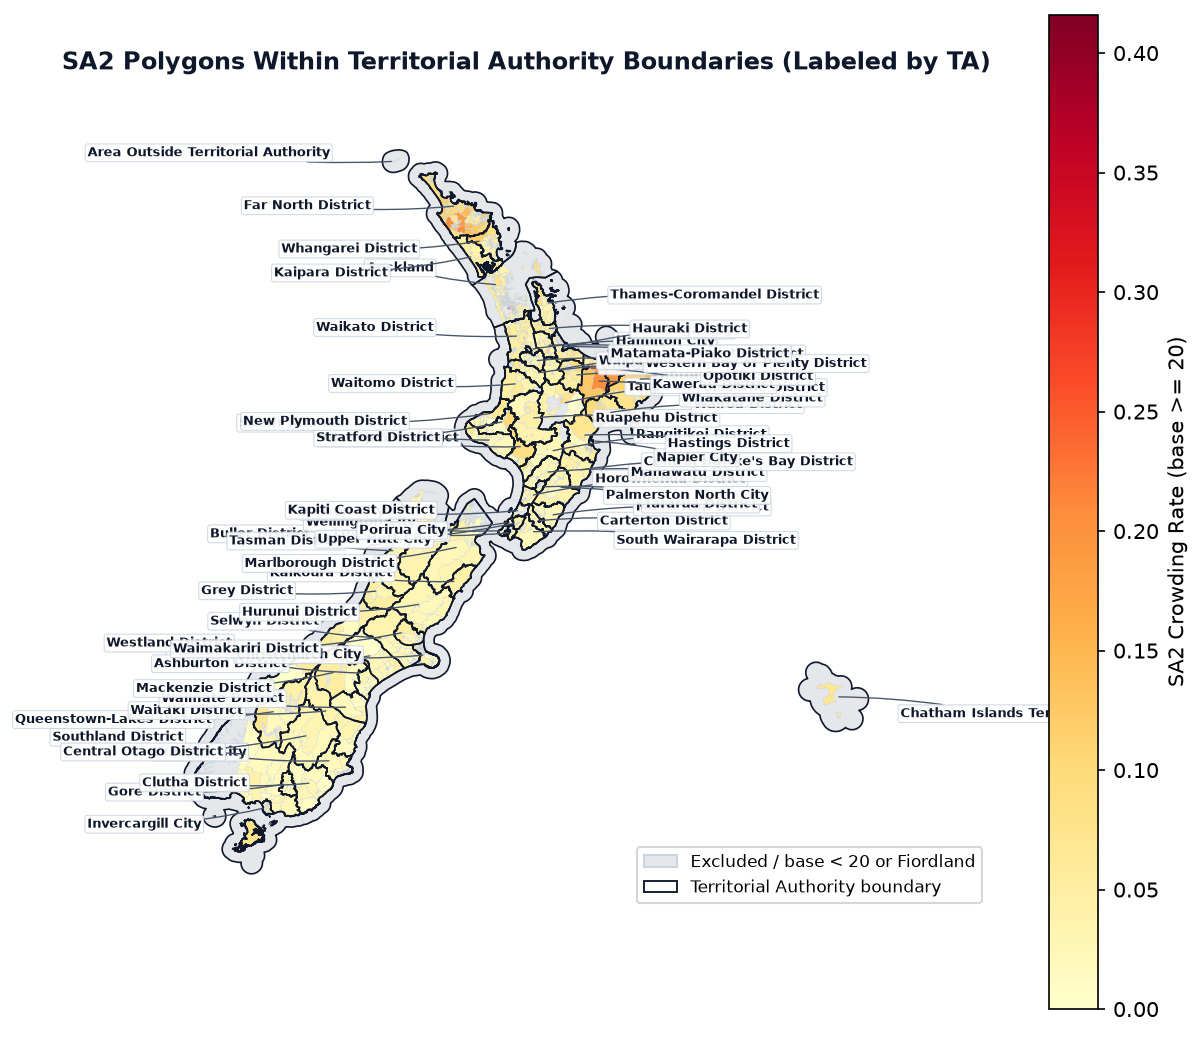

In [23]:
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# 1. Load SA2 polygons and align CRS to ta_gdf (EPSG:2193)
sa2_path = DATA / "statistical-area-2-2023-generalised.shp"
sa2_plot_gdf = gpd.read_file(sa2_path)
if sa2_plot_gdf.crs != ta_gdf.crs:
    sa2_plot_gdf = sa2_plot_gdf.to_crs(ta_gdf.crs)

sa2_code_col = next(
    c for c in ("sa2_code", "SA22023_V1_00", "SA22023_V1", "SA22023_V1_")
    if c in sa2_plot_gdf.columns
)
ta_name_col = next(
    c for c in ("TA2023_V_1", "TA2023_V_2", "ta_name", "TA2023_V1_00_NAME", "TA2023_V1_NAME", "NAME")
    if c in ta_gdf.columns
)

sa2_plot_gdf[sa2_code_col] = sa2_plot_gdf[sa2_code_col].astype(str).str.strip()

# Merge crowding_rate, crowding_base, and sa2_name so small-base / Fiordland SA2s can be masked
merge_cols = [c for c in ("sa2_code", "sa2_name", "crowding_rate", "crowding_base") if c in df.columns]
if "crowding_rate" in merge_cols:
    df_key = df[merge_cols].copy()
    df_key["sa2_code"] = df_key["sa2_code"].astype(str).str.strip()
    df_key = df_key.drop_duplicates(subset=["sa2_code"])
    sa2_plot_gdf = sa2_plot_gdf.drop(columns=[c for c in merge_cols if c != "sa2_code"], errors="ignore")
    sa2_plot_gdf = sa2_plot_gdf.merge(df_key, left_on=sa2_code_col, right_on="sa2_code", how="left")

fig, ax = plt.subplots(figsize=(8.5, 10.5), dpi=150)
fig.patch.set_facecolor("white")
ax.set_facecolor("#f8fafc")

min_base = 20

if "crowding_rate" in sa2_plot_gdf.columns:
    valid_rate = sa2_plot_gdf["crowding_rate"].notna()
    if "crowding_base" in sa2_plot_gdf.columns:
        valid_rate = valid_rate & sa2_plot_gdf["crowding_base"].notna() & (sa2_plot_gdf["crowding_base"] >= min_base)
    if "sa2_name" in sa2_plot_gdf.columns:
        valid_rate = valid_rate & ~sa2_plot_gdf["sa2_name"].astype(str).str.contains("fiordland", case=False, na=False)

    # Low-base, empty, or Fiordland SA2s plot as neutral grey instead of dark red
    sa2_plot_gdf.loc[~valid_rate].plot(
        ax=ax,
        color="#e5e7eb",
        edgecolor="#cbd5e1",
        linewidth=0.15,
        zorder=1,
    )

    sa2_plot_gdf.loc[valid_rate].plot(
        column="crowding_rate",
        ax=ax,
        cmap="YlOrRd",
        legend=True,
        legend_kwds={"label": f"SA2 Crowding Rate (base >= {min_base})", "shrink": 0.65},
        edgecolor="#cbd5e1",
        linewidth=0.15,
        zorder=1,
    )
else:
    sa2_plot_gdf.plot(ax=ax, color="#e2e8f0", edgecolor="#94a3b8", linewidth=0.15, zorder=1)

# 2. Territorial Authority boundaries on top
ta_gdf.boundary.plot(ax=ax, color="#0f172a", linewidth=0.8, zorder=2)

# 3. Compute bounds once, then place offset TA leader labels
xmin, ymin, xmax, ymax = sa2_plot_gdf.total_bounds
x_mid = (xmin + xmax) / 2.0

ta_valid = ta_gdf[ta_gdf.geometry.notna() & ~ta_gdf.geometry.is_empty].copy()
anchors = []
for _, ta_row in ta_valid.iterrows():
    ta_label = str(ta_row[ta_name_col]).strip()
    if not ta_label or ta_label.lower() in ("nan", "none"):
        continue
    pt = ta_row.geometry.representative_point()
    anchors.append((pt.x, pt.y, ta_label))

anchors.sort(key=lambda item: item[1])

left_idx = 0
right_idx = 0
for x, y, ta_label in anchors:
    if x <= x_mid:
        offset_x = -140_000 - (left_idx % 2) * 45_000
        offset_y = ((left_idx % 5) - 2) * 18_000
        ha = "right"
        left_idx += 1
    else:
        offset_x = 140_000 + (right_idx % 2) * 45_000
        offset_y = ((right_idx % 5) - 2) * 18_000
        ha = "left"
        right_idx += 1

    ax.annotate(
        ta_label,
        xy=(x, y),
        xytext=(x + offset_x, y + offset_y),
        ha=ha,
        va="center",
        fontsize=6.2,
        fontweight="bold",
        color="#0f172a",
        bbox=dict(
            boxstyle="round,pad=0.18",
            facecolor="white",
            edgecolor="#cbd5e1",
            linewidth=0.5,
            alpha=0.92,
        ),
        arrowprops=dict(
            arrowstyle="-",
            color="#475569",
            lw=0.65,
            shrinkA=0,
            shrinkB=2,
            connectionstyle="arc3,rad=0.05",
        ),
        zorder=4,
    )

legend_handles = [
    mpatches.Patch(facecolor="#e5e7eb", edgecolor="#cbd5e1", label=f"Excluded / base < {min_base} or Fiordland"),
    mpatches.Patch(facecolor="none", edgecolor="#0f172a", linewidth=0.9, label="Territorial Authority boundary"),
]
ax.legend(handles=legend_handles, loc="lower right", frameon=True, facecolor="white", fontsize=8)

ax.set_xlim(xmin - 260_000, xmax + 260_000)
ax.set_ylim(ymin - 80_000, ymax + 80_000)
ax.set_axis_off()
ax.set_title(
    "SA2 Polygons Within Territorial Authority Boundaries (Labeled by TA)",
    fontsize=11.5,
    fontweight="bold",
    color="#0f172a",
    pad=10,
)

plt.tight_layout()
plt.show()

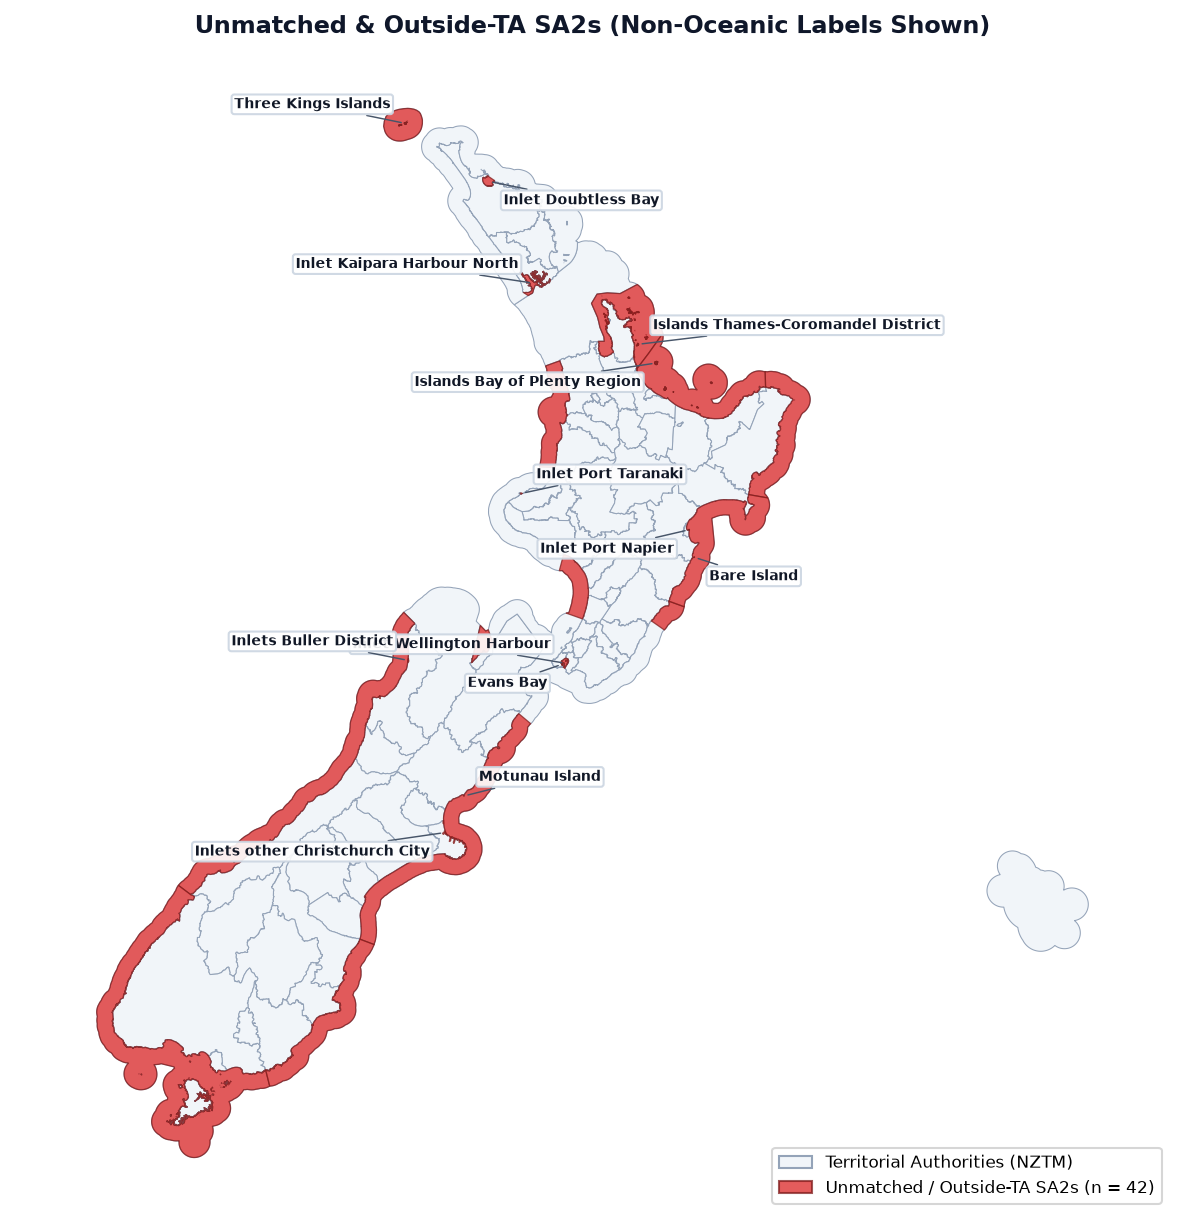

In [24]:
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# Match SA2 code column in sa2_geom and merge onto unmatched_df
sa2_code_col = next(
    c for c in ("sa2_code", "SA22023_V1_00", "SA22023_V1", "SA22023_V1_") if c in sa2_geom.columns
)
map_unmatched = sa2_geom[[sa2_code_col, "geometry"]].copy()
map_unmatched[sa2_code_col] = map_unmatched[sa2_code_col].astype(str).str.strip()

unmatched_join = unmatched_df.copy()
unmatched_join["sa2_code"] = unmatched_join["sa2_code"].astype(str).str.strip()

unmatched_gdf = map_unmatched.merge(
    unmatched_join,
    left_on=sa2_code_col,
    right_on="sa2_code",
    how="inner",
)
if unmatched_gdf.crs != ta_gdf.crs:
    unmatched_gdf = unmatched_gdf.to_crs(ta_gdf.crs)

fig, ax = plt.subplots(figsize=(8, 10), dpi=150)
fig.patch.set_facecolor("white")
ax.set_facecolor("#f8fafc")

# Base context: Territorial Authority polygons & boundaries
ta_gdf.plot(ax=ax, color="#f1f5f9", edgecolor="#94a3b8", linewidth=0.5, zorder=1)

# Highlight the 42 unmatched / outside-TA SA2s
unmatched_gdf.plot(
    ax=ax,
    color="#dc2626",
    edgecolor="#7f1d1d",
    linewidth=0.6,
    alpha=0.75,
    zorder=2,
)

# Label non-oceanic unmatched/outside-TA SA2s so coastal/land features stay readable
# (oceanic polygons cover huge sea extents and crowd the map if all 42 are labeled)
label_candidates = unmatched_gdf[
    ~unmatched_gdf["sa2_name"].astype(str).str.startswith("Oceanic ")
    & unmatched_gdf.geometry.notna()
    & ~unmatched_gdf.geometry.is_empty
].copy()

pts = label_candidates.geometry.representative_point()

for idx, ((_, row), pt) in enumerate(zip(label_candidates.iterrows(), pts)):
    dy = 28_000 if idx % 2 == 0 else -28_000
    dx = 22_000 if idx % 3 == 0 else -22_000
    short_label = str(row["sa2_name"]).replace(" Area Outside Territorial Authority", "")
    ax.annotate(
        short_label,
        xy=(pt.x, pt.y),
        xytext=(pt.x + dx, pt.y + dy),
        fontsize=6.5,
        fontweight="bold",
        color="#111827",
        ha="left" if dx >= 0 else "right",
        va="center",
        bbox=dict(boxstyle="round,pad=0.2", facecolor="white", edgecolor="#cbd5e1", alpha=0.9),
        arrowprops=dict(arrowstyle="-", color="#475569", lw=0.7),
        zorder=4,
    )

legend_handles = [
    mpatches.Patch(facecolor="#f1f5f9", edgecolor="#94a3b8", label="Territorial Authorities (NZTM)"),
    mpatches.Patch(facecolor="#dc2626", edgecolor="#7f1d1d", alpha=0.75,
                   label=f"Unmatched / Outside-TA SA2s (n = {len(unmatched_gdf)})"),
]
ax.legend(handles=legend_handles, loc="lower right", frameon=True, facecolor="white", fontsize=8)

xmin, ymin, xmax, ymax = ta_gdf.total_bounds
ax.set_xlim(xmin - 120_000, xmax + 120_000)
ax.set_ylim(ymin - 80_000, ymax + 80_000)
ax.set_axis_off()
ax.set_title(
    "Unmatched & Outside-TA SA2s (Non-Oceanic Labels Shown)",
    fontsize=11.5,
    fontweight="bold",
    color="#0f172a",
    pad=10,
)

plt.tight_layout()
plt.show()

In [25]:
import json
import pandas as pd

spec_path = mp2.OUT / "feature_spec.json"
frame_path = mp2.OUT / "analysis_frame_features.csv"

assert spec_path.exists(), f"Missing spec file: {spec_path}"
assert frame_path.exists(), f"Missing frame file: {frame_path}"

spec = json.loads(spec_path.read_text())
out_df = pd.read_csv(frame_path, dtype={"sa2_code": str})

required_ids = ["sa2_code", "sa2_name", "ta_name"]
missing_ids = [c for c in required_ids if c not in out_df.columns]
missing_numeric = [c for c in spec.get("numeric", []) if c not in out_df.columns]
missing_cat = [c for c in spec.get("categorical", []) if c not in out_df.columns]

print("=== Output Readiness Check ===")
print(f"Rows in analysis_frame_features.csv : {len(out_df):,}")
print(f"Missing ID / TA columns              : {missing_ids if missing_ids else 'None (sa2_code, sa2_name, ta_name present)'}")
print(f"Missing numeric features             : {len(missing_numeric)}")
print(f"Missing categorical features         : {len(missing_cat)}")
print(f"spec['categorical']                  : {spec.get('categorical', [])}")
print(f"spec['numeric'] count                : {len(spec.get('numeric', []))}")

# Check that no target or definition columns leaked into model features
feature_cols = set(spec.get("numeric", [])) | set(spec.get("categorical", []))
target_cols = {spec.get("target")} | set(DERIVED_TARGET) | {
    c for c in out_df.columns if c.startswith(TARGET_PREFIX)
}
leaked = sorted(feature_cols & target_cols)
assert not leaked, f"Target columns leaked into features: {leaked}"
print("Target leakage check                 : Passed (0 target columns in features)")

print("\n=== Sample SA2 -> TA Mapping ===")
sample_cols = [c for c in ["sa2_code", "sa2_name", "ta_name", "crowding_rate"] if c in out_df.columns]
print(out_df[sample_cols].head(10).to_string(index=False))

=== Output Readiness Check ===
Rows in analysis_frame_features.csv : 2,395
Missing ID / TA columns              : None (sa2_code, sa2_name, ta_name present)
Missing numeric features             : 0
Missing categorical features         : 0
spec['categorical']                  : ['sa2_code', 'ta_name']
spec['numeric'] count                : 36
Target leakage check                 : Passed (0 target columns in features)

=== Sample SA2 -> TA Mapping ===
sa2_code             sa2_name                 ta_name  crowding_rate
  187600                Tiroa        Waitomo District       0.000000
  223400             Mowhanau      Whanganui District       0.012270
  101801            Whakarara      Far North District       0.114286
  174701               Okauia Matamata-Piako District       0.025641
  256600  Homebush-Te Ore Ore      Masterton District       0.028571
  309300       Westport Rural         Buller District       0.022346
  357601           Whitestone      Southland District       0.